### MCP

**MCP(Model Context Protocol)** 는 AI 애플리케이션이 외부 도구와 데이터를 활용하기 위한 표준 통신 규약이다.

AI 애플리케이션마다 도구 연결 방식이 다르면 같은 기능도 앱에 맞춰 연결해야 한다. MCP는 이 연결 방식을 표준화하여, **하나의 서버가 제공하는 기능을 여러 MCP 지원 앱에서 재사용**할 수 있게 한다.

예를 들어 날씨 조회 기능을 MCP 서버로 만들면, LangGraph로 만든 Agent와 Claude Code가 같은 서버를 사용할 수 있다. 각 애플리케이션은 서버가 제공하는 Tool 목록과 입력 형식을 조회한 뒤 필요한 Tool을 호출한다.

```text
LangGraph Agent ──┐
                  ├── 날씨 MCP 서버 ── TOOL
Claude Code ──────┘
```


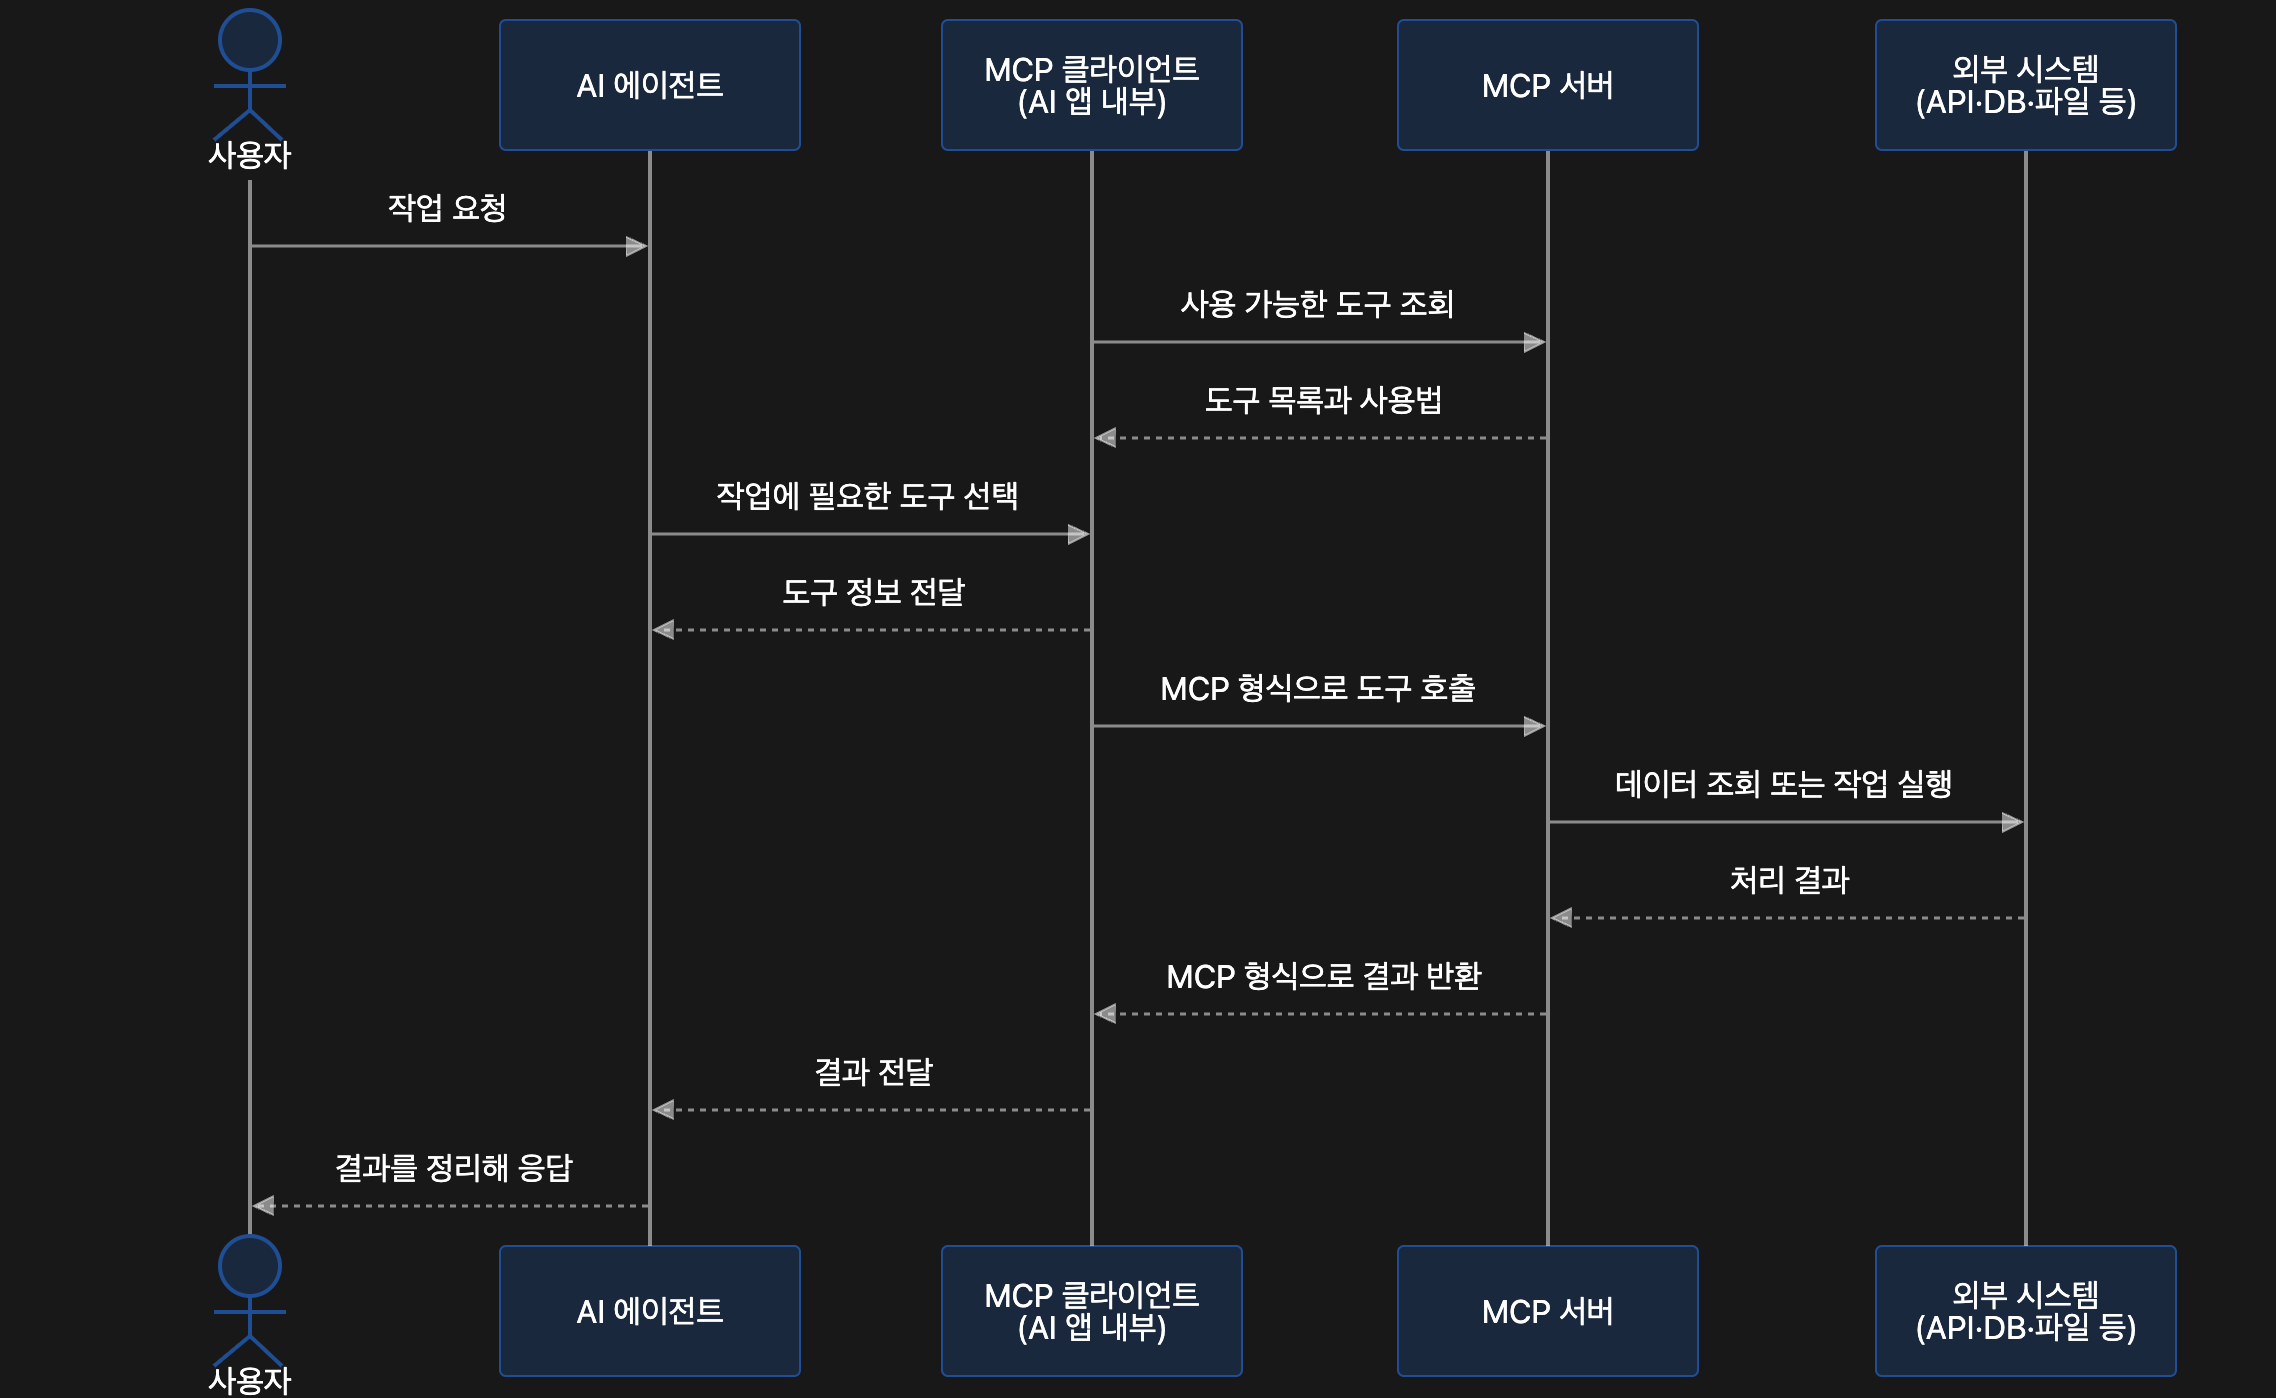

### Tool Calling과 MCP의 관계

Tool Calling은 **LLM이 외부 도구를 활용하기 위한 기능**이다.   
MCP는 **AI 애플리케이션이 외부 도구와 데이터를 활용하기 위한 표준 통신 규약**이다.

| 비교 | LangChain `@tool`로 만든 Tool | MCP 서버가 제공하는 Tool |
|---|---|---|
| 등록 | Python 함수를 LangChain Tool로 등록 | 서버의 기능을 MCP Tool로 등록 |
| 호출 | 애플리케이션이 등록된 함수를 호출 | 애플리케이션의 요청을 받아 서버가 실행 |
| 재사용 | 함수나 패키지를 가져와 LangChain 앱에서 사용 | MCP 지원 앱에서 서버에 연결해 사용 |
| 적합한 경우 | LangChain 앱에 필요한 함수나 API를 직접 도구로 연결할 때 | 여러 MCP 지원 앱에서 같은 도구를 공유하거나 기존 MCP 서버의 도구를 사용할 때 |


### MCP의 구성 요소

MCP의 연결 구조에는 **Host, Client, Server**라는 세 가지 역할이 있다. 사용자가 이용하는 AI 앱이 Host이고, Host 안의 Client가 도구와 데이터를 제공하는 Server와 통신한다.

| 구성 요소 | 역할 | 이 수업의 예 |
|---|---|---|
| Host | 모델·사용자 대화·도구 사용을 관리하는 앱 | LangGraph Agent 앱, Claude Code |
| Client | Host 안에서 MCP 서버와 통신 | `MultiServerMCPClient`가 관리하는 연결 |
| Server | Tool·Resource·Prompt를 제공하는 프로그램 | `weather_server.py` |

모델은 서버와 직접 통신하지 않고, Host가 모델의 요청을 받아 Client를 통해 실행한다.


### Tool, Resource, Prompt

MCP 서버는 **Tool, Resource, Prompt**라는 세 가지 형태로 기능과 데이터를 제공할 수 있다. Tool은 실행 가능한 함수, Resource는 읽을 수 있는 데이터, Prompt는 재사용할 수 있는 메시지 템플릿이다.

| 기능 | 제공하는 것 | 주로 사용하는 주체 | 예 |
|---|---|---|---|
| Tool | 실행 가능한 함수 | 모델이 호출을 제안하고 앱이 실행 | 현재 날씨 조회, 예보 조회 |
| Resource | URI로 읽을 수 있는 데이터 | 앱이 필요한 데이터를 선택해 사용 | 지원 도시 목록 |
| Prompt | 인자를 받아 만드는 메시지 템플릿 | 사용자나 앱이 선택 | 도시별 날씨 요약 요청 |

서버가 세 기능을 모두 구현할 필요는 없다. Client마다 지원 범위도 다르다.

`get_tools()`는 Tool만 가져온다. Resource와 Prompt는 따로 읽어 모델에 전달해야 하며, Prompt를 가져오는 것만으로 모델이 실행되지는 않는다.


### MCP 메시지의 구조

MCP의 Client와 Server는 **JSON-RPC(Remote Procedure Call) 2.0** 형식으로 메시지를 주고받는다. JSON-RPC는 JSON에 작업 이름과 입력값을 담아 요청하고, 결과를 응답하는 규칙이다. MCP는 여기에 도구 목록 조회를 위한 `tools/list`, 도구 실행을 위한 `tools/call` 등의 작업과 데이터 형식을 정의한다.

연결 초기화를 마치면 Client는 `tools/list`로 도구 목록과 입력 형식을 확인하고, 필요한 도구를 `tools/call`로 호출할 수 있다. 아래는 서울 날씨를 조회하는 요청과 응답의 구조를 단순화한 예다.

**Client → Server: 도구 실행 요청**

```json
{
  "jsonrpc": "2.0",
  "id": 1,
  "method": "tools/call",
  "params": {
    "name": "get_current_weather",
    "arguments": {
      "city": "서울"
    }
  }
}
```

**Server → Client: 실행 결과 응답**

```json
{
  "jsonrpc": "2.0",
  "id": 1,
  "result": {
    "content": [
      {
        "type": "text",
        "text": "서울의 현재 기온은 22°C, 습도는 50%입니다."
      }
    ]
  }
}
```

| 필드 | 의미 |
|---|---|
| `jsonrpc` | JSON-RPC 형식의 버전이며, MCP 자체의 버전과는 다름 |
| `id` | 어떤 요청에 대한 응답인지 연결하는 식별자 |
| `method` | MCP 작업 이름. `tools/call`은 도구 실행 요청 |
| `params.name` | 실행할 도구의 이름 |
| `params.arguments` | 도구에 전달할 입력값 |
| `result` | 요청이 정상 처리되었을 때 반환하는 결과 데이터 |
| `result.content` | 도구가 반환한 콘텐츠 목록. 위 예시는 텍스트 하나를 포함 |


### 필요한 패키지 설치

`mcp`는 Python으로 MCP 서버를 만들고 서버와 통신할 수 있게 하는 SDK다. SDK에 포함된 `FastMCP`는 Python 함수에 데코레이터를 붙여 Tool·Resource·Prompt를 등록할 수 있게 해 준다.

`langchain-mcp-adapters`는 MCP 서버의 Tool을 LangChain Tool로 변환해 LangChain·LangGraph Agent에 연결해 주는 라이브러리다.

```bash
pip install "mcp==1.30.0" "langchain-mcp-adapters==0.3.2"
```

노트북이 있는 폴더를 작업 폴더로 두고 실행한다. 서버 파일은 같은 폴더의 `mcp_examples/weather_server.py`에 둔다.


In [1]:
import json

from dotenv import load_dotenv
from langchain_mcp_adapters.client import MultiServerMCPClient

load_dotenv()
MODEL_NAME = "gemini-3.6-flash"


### 날씨 서버 실행하기

제공된 `mcp_examples/weather_server.py`는 서울·부산·제주의 날씨를 조회하는 Tool 두 개를 제공하는 MCP 서버다.

서버는 도시별로 정해 둔 **실습용 가상 날씨 데이터**를 반환한다. 실제 날씨를 조회하지 않으며, 외부 날씨 API나 API 키는 필요하지 않다.

| Tool | 입력 | 반환하는 정보 |
|---|---|---|
| `get_current_weather` | `city` | 현재 기온·습도 |
| `get_weather_forecast` | `city` | 예보의 최저·최고 기온, 강수 확률 |

노트북과 같은 Python 환경을 활성화한 별도 터미널에서 노트북이 있는 폴더로 이동한 뒤 실행한다.

```bash
python mcp_examples/weather_server.py
```

서버는 `http://127.0.0.1:8000/mcp`에서 요청을 받는다. 실습하는 동안 서버 터미널을 열어 두고, 실습이 끝나면 그 터미널에서 `Ctrl+C`로 종료한다.


### 날씨 서버에 연결하기

노트북에서 실행 중인 MCP 서버의 주소로 연결한다. 서버를 실행한 컴퓨터에서 아래 셀을 실행한다.

`get_tools()`는 서버의 Tool 목록을 가져온다. 날씨 Tool이나 LLM은 아직 호출하지 않는다.


In [2]:
weather_connection = {
    "transport": "streamable_http",
    "url": "http://127.0.0.1:8000/mcp",
    "timeout": 10,
}

weather_client = MultiServerMCPClient({"weather": weather_connection})
weather_tools = await weather_client.get_tools()
weather_tool_map = {tool.name: tool for tool in weather_tools}

for tool in weather_tools:
    print("이름:", tool.name)
    print("설명:", tool.description)
    print("입력:", json.dumps(tool.args, ensure_ascii=False, indent=2))
    print()


이름: get_current_weather
설명: 서울·부산·제주 중 한 도시의 현재 기온과 습도를 반환한다.
입력: {
  "city": {
    "enum": [
      "서울",
      "부산",
      "제주"
    ],
    "title": "City",
    "type": "string"
  }
}

이름: get_weather_forecast
설명: 서울·부산·제주 중 한 도시의 최저·최고 기온과 강수 확률을 반환한다.
입력: {
  "city": {
    "enum": [
      "서울",
      "부산",
      "제주"
    ],
    "title": "City",
    "type": "string"
  }
}



### LLM 없이 Tool 직접 호출하기

도구의 이름과 입력 형식을 알고 있다면 모델 없이 직접 호출할 수 있다. 연결 문제와 모델의 도구 선택 문제를 나누어 확인할 때도 유용하다.

서울의 현재 날씨와 예보를 조회한다. 반환값에는 도시, 날씨 값과 단위가 포함된다.

어댑터의 반환값은 텍스트 또는 콘텐츠 블록 목록일 수 있다.


In [ ]:
current_result = await weather_tool_map["get_current_weather"].ainvoke({"city": "서울"})
print("현재 날씨:", current_result)

forecast_result = await weather_tool_map["get_weather_forecast"].ainvoke(
    {"city": "서울"}
)
print("예보:", forecast_result)


현재 날씨: [{'type': 'text', 'text': '{\n  "city": "서울",\n  "current": {\n    "temperature": 22,\n    "humidity": 50\n  },\n  "units": {\n    "temperature": "°C",\n    "humidity": "%"\n  }\n}', 'id': 'lc_980c814a-32f8-4cda-8fd6-e555c52cfffc'}]
예보: [{'type': 'text', 'text': '{\n  "city": "서울",\n  "forecast": {\n    "min_temperature": 18,\n    "max_temperature": 25,\n    "rain_probability": 20\n  },\n  "units": {\n    "min_temperature": "°C",\n    "max_temperature": "°C",\n    "rain_probability": "%"\n  }\n}', 'id': 'lc_f53c965b-d013-4ed3-a1af-be246f2272e0'}]


Failed to multipart ingest runs: langsmith.utils.LangSmithRateLimitError: Rate limit exceeded for https://api.smith.langchain.com/runs/multipart. HTTPError('429 Client Error: Too Many Requests for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Too many requests: tenant exceeded usage limits: Monthly unique traces usage limit exceeded"}\n')trace=01a1518f-a225-7653-9e13-cece11ae525b,id=01a1518f-a225-7653-9e13-cece11ae525b; trace=01a1518f-a429-7692-855c-6e63e4738b5c,id=01a1518f-a429-7692-855c-6e63e4738b5c
Failed to send compressed multipart ingest: langsmith.utils.LangSmithRateLimitError: Rate limit exceeded for https://api.smith.langchain.com/runs/multipart. HTTPError('429 Client Error: Too Many Requests for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Too many requests: tenant exceeded usage limits: Monthly unique traces usage limit exceeded"}\n')trace=01a1518f-a429-7692-855c-6e63e4738b5c,id=01a1518f-a429-7692-855c-6e63e4738b5c


### Agent에서 MCP Tool 사용하기

`create_agent`에 모델과 MCP 서버에서 가져온 Tool을 전달해 Agent를 만든다. Agent는 사용자 요청에 따라 필요한 Tool을 선택하고 실행한다.

MCP 어댑터의 Tool은 비동기로 실행하므로 Agent를 호출할 때 `await agent.ainvoke(...)`를 사용한다.


In [ ]:
from langchain.agents import create_agent
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(model=MODEL_NAME)
weather_agent = create_agent(
    model=llm,
    tools=weather_tools,
    system_prompt=(
        "날씨는 반드시 도구로 조회하세요. 현재 값과 예보를 구분하고 "
        "단위를 포함해 한국어로 답하세요. "
        "조회에 실패하거나 값이 없으면 추측하지 말고 확인할 수 없다고 안내하세요."
    ),
)

weather_response = await weather_agent.ainvoke(
    {"messages": [("user", "서울의 현재 날씨와 예보를 알려줘.")]},
    config={"recursion_limit": 12},
)
print(weather_response["messages"][-1].text)


Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.
Failed to send compressed multipart ingest: langsmith.utils.LangSmithRateLimitError: Rate limit exceeded for https://api.smith.langchain.com/runs/multipart. HTTPError('429 Client Error: Too Many Requests for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Too many requests: tenant exceeded usage limits: Monthly unique traces usage limit exceeded"}\n')trace=01a15191-092e-7cd1-af93-0d43bee23e54,id=01a15191-092e-7cd1-af93-0d43bee23e54; trace=01a15191-092e-7cd1-af93-0d43bee23e54,id=01a15191-0930-7972-b4fa-0dc9c8407141; trace=01a15191-092e-7cd1-af93-0d43bee23e54,id=01a15191-0ac2-77f2-a8cf-f9b281408233


서울의 현재 날씨와 날씨 예보입니다.

**현재 날씨**
- 기온: 22°C
- 습도: 50%

**날씨 예보**
- 최저 기온: 18°C
- 최고 기온: 25°C
- 강수 확률: 20%


Failed to send compressed multipart ingest: langsmith.utils.LangSmithRateLimitError: Rate limit exceeded for https://api.smith.langchain.com/runs/multipart. HTTPError('429 Client Error: Too Many Requests for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Too many requests: tenant exceeded usage limits: Monthly unique traces usage limit exceeded"}\n')trace=01a15191-092e-7cd1-af93-0d43bee23e54,id=01a15191-0ac2-77f2-a8cf-f9b281408233; trace=01a15191-092e-7cd1-af93-0d43bee23e54,id=01a15191-0930-7972-b4fa-0dc9c8407141; trace=01a15191-092e-7cd1-af93-0d43bee23e54,id=01a15191-134c-7090-80a3-fcb0925f11f0; trace=01a15191-092e-7cd1-af93-0d43bee23e54,id=01a15191-134c-7090-80a3-fcc0670d6d4b; trace=01a15191-092e-7cd1-af93-0d43bee23e54,id=01a15191-134d-7b51-9bdf-e0f1777d44c0; trace=01a15191-092e-7cd1-af93-0d43bee23e54,id=01a15191-134d-7b51-9bdf-e105d8d62c50; trace=01a15191-092e-7cd1-af93-0d43bee23e54,id=01a15191-134d-7b51-9bdf-e0f1777d44c0; trace=01a15191-092e-7cd1-af93-0d43bee23e54

In [5]:
for message in weather_response["messages"]:
    if getattr(message, "tool_calls", None):
        print("모델의 호출 요청:", message.tool_calls)
    elif message.type == "tool":
        print("Tool 실행 결과:", message.text)


모델의 호출 요청: [{'name': 'get_current_weather', 'args': {'city': '서울'}, 'id': 'call_6291806', 'type': 'tool_call'}, {'name': 'get_weather_forecast', 'args': {'city': '서울'}, 'id': 'call_6291807', 'type': 'tool_call'}]
Tool 실행 결과: {
  "city": "서울",
  "current": {
    "temperature": 22,
    "humidity": 50
  },
  "units": {
    "temperature": "°C",
    "humidity": "%"
  }
}
Tool 실행 결과: {
  "city": "서울",
  "forecast": {
    "min_temperature": 18,
    "max_temperature": 25,
    "rain_probability": 20
  },
  "units": {
    "min_temperature": "°C",
    "max_temperature": "°C",
    "rain_probability": "%"
  }
}


### 날씨 MCP 서버 살펴보기

`mcp_examples/weather_server.py`에서 다음 부분을 확인한다.

| 코드 | 역할 |
|---|---|
| `FastMCP(...)` | MCP 서버 생성 |
| `@mcp.tool()` | 함수를 Tool로 등록 |
| `@mcp.resource(...)` | 읽을 데이터를 Resource로 등록 |
| `@mcp.prompt()` | 메시지 템플릿을 Prompt로 등록 |
| `mcp.run(...)` | 서버 실행 |

Tool로 등록한 함수의 이름과 docstring은 Tool의 이름과 설명이 된다.


### Resource 읽기

서버에서 지원 도시 목록을 읽는다. `get_resources()`는 목록을 반환하므로 첫 번째 항목을 문자열로 꺼낸다.


In [ ]:
resources = await weather_client.get_resources("weather", uris="weather://cities")
cities_text = resources[0].as_string()
print(cities_text)


### Prompt 읽기

`get_prompt()`에 도시를 전달해 날씨 요약 요청을 가져온다. 이 서버는 메시지 하나를 반환하므로 첫 번째 메시지의 `.text`를 확인한다. 아직 LLM은 호출하지 않는다.


In [ ]:
weather_messages = await weather_client.get_prompt(
    "weather", "weather_briefing", arguments={"city": "서울"}
)
prompt_text = weather_messages[0].text
print(prompt_text)


### 읽어 온 내용을 Agent에 전달하기

지원 도시 정보와 Prompt의 문장을 합쳐 Agent에 전달한다.


In [ ]:
request = f"지원 도시:\n{cities_text}\n\n{prompt_text}"

briefing_response = await weather_agent.ainvoke(
    {"messages": [("user", request)]},
    config={"recursion_limit": 12},
)
print(briefing_response["messages"][-1].text)


### Claude Code에서 MCP 사용하기

Claude Code는 MCP Host 역할을 한다. 앞에서 실행한 날씨 MCP 서버에 같은 주소로 연결할 수 있다.

Claude Code를 설치하고 로그인한 뒤, 터미널을 노트북이 있는 폴더에서 연다.

```bash
claude --version
claude mcp add --help
```

Claude Code는 자체 모델과 인증을 사용한다. 앞에서 만든 LangGraph Agent나 `GOOGLE_API_KEY`를 Claude Code에 전달하는 과정은 필요하지 않다.


### 날씨 서버 등록하기

날씨 서버를 실행해 둔 상태에서 다른 터미널을 열고, 노트북이 있는 폴더에서 다음 명령을 실행한다.

```bash
claude mcp add --transport http --scope local weather http://127.0.0.1:8000/mcp
```

### Claude Code에서 연결 확인하고 호출하기

터미널에서 등록 내용을 확인한 뒤 Claude Code를 실행한다.

```bash
claude mcp list
claude mcp get weather
claude
```

Claude Code 대화창에서 다음을 입력한다.

```
/mcp
```

`weather`의 연결 상태와 제공 Tool을 확인한 뒤 요청한다.

```
weather의 get_current_weather와 get_weather_forecast 도구를 사용해서
서울의 현재 날씨와 예보를 알려줘.
```

도구 실행 승인을 요청하면 호출 이름과 인자를 확인한다. 답변에 단위가 포함되는지, 대화에 두 Tool의 호출 기록이 남는지 확인한다.

실행 중인 같은 MCP 서버의 Tool을 LangGraph Agent와 Claude Code가 각각 호출했다는 점이 핵심이다.


### Smithery

**Smithery**는 MCP 서버를 검색하고 AI 애플리케이션에 연결할 수 있게 돕는 서비스다. 앞에서 만든 날씨 서버처럼, 다른 개발자가 공개한 MCP 서버의 기능도 가져와 사용할 수 있다.

- 웹 검색, 개발 문서 조회, 브라우저 제어 등 필요한 기능을 제공하는 서버를 찾는다.
- 서버의 설명과 제공 Tool, 연결 방법을 확인한다.
- 필요한 서비스 계정을 연결하고 인증 정보를 관리한다.

예를 들어 Agent에 웹 검색 기능을 추가하고 싶다면, Smithery에서 검색 기능을 제공하는 MCP 서버를 찾아 연결할 수 있다.

**MCP는 통신 규약이고, Smithery는 MCP 서버를 찾고 연결하는 서비스**다. mcp를 서버에 직접 연결할 수도 있으므로 MCP를 사용하기 위해 Smithery가 반드시 필요한 것은 아니다.


### A2A 프로토콜

**A2A(Agent2Agent)** 는 독립적인 AI Agent가 서로 업무를 요청하고, 진행 상태와 결과를 주고받기 위한 표준 통신 규약이다. 사용하는 모델이나 개발 프레임워크가 달라도 양쪽이 A2A를 지원하면 같은 통신 규칙으로 협업할 수 있다.

예를 들어 여행 계획 Agent가 외부 서비스의 숙소 조사 Agent에게 “부산에서 예산에 맞는 숙소 후보를 비교해 줘”라고 요청할 수 있다. 숙소 조사 Agent는 필요한 정보를 찾고 비교한 뒤 결과를 전달하며, 조건이 부족하면 날짜나 예산을 추가로 물어볼 수 있다.

| 구분 | MCP | A2A |
|---|---|---|
| 주된 연결 대상 | AI 애플리케이션과 도구·데이터 | 독립적인 Agent 사이 |
| 주된 역할 | 외부 기능 호출과 데이터 활용 | 업무 위임, 진행 상태와 결과 교환 |
| 예시 | 숙소 검색 Tool에 지역과 날짜를 전달 | 숙소 조사 Agent에게 후보 비교를 요청 |

두 프로토콜은 함께 사용할 수 있다. 여행 계획 Agent와 숙소 조사 Agent는 A2A로 소통하고, 숙소 조사 Agent는 내부에서 MCP로 검색 도구를 사용할 수 있다.
